# Lab 05: Predict late deliveries

In [22]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from latedeliveries.pipeline import load_orders

ROOT = Path.cwd().parent
reports = ROOT / "reports"

# Late Order rate

3000 orders, 468 late (15.6%)

Share of values missing:
prep_minutes       0.063
customer_rating    0.496


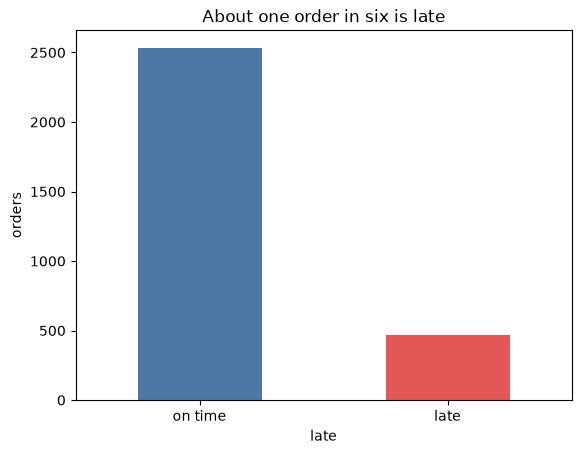

In [23]:
orders = load_orders()
rate = orders["late"].mean()
print(f"{len(orders)} orders, {orders['late'].sum()} late ({rate:.1%})")
print()
print("Share of values missing:")
print(orders.isna().mean().round(3)[lambda s: s > 0].to_string())

counts = orders["late"].map({0: "on time", 1: "late"}).value_counts()
counts.plot.bar(color=["#4c78a8", "#e45756"], rot=0)
plt.ylabel("orders")
plt.title("About one order in six is late")
plt.show()

# Model comparision 

In [24]:
cv = pd.read_csv(reports / "cv_results.csv").set_index("model")
table = pd.DataFrame(
    {
        metric: cv[f"{metric}_mean"].round(3).astype(str)
        + " ± "
        + cv[f"{metric}_std"].round(3).astype(str)
        for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]
    }
)
print(table.to_string())

                             accuracy      precision         recall             f1        roc_auc
model                                                                                            
baseline_dummy          0.844 ± 0.001      0.0 ± 0.0      0.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
logistic_regression     0.862 ± 0.008  0.654 ± 0.065  0.242 ± 0.053  0.352 ± 0.064  0.795 ± 0.034
logistic_balanced       0.737 ± 0.019  0.333 ± 0.027  0.681 ± 0.049  0.447 ± 0.034  0.795 ± 0.034
random_forest           0.859 ± 0.008  0.736 ± 0.121  0.148 ± 0.036  0.246 ± 0.056  0.786 ± 0.037
hist_gradient_boosting  0.851 ± 0.006  0.544 ± 0.036  0.288 ± 0.037  0.375 ± 0.036  0.754 ± 0.024


 # Cost against threshold

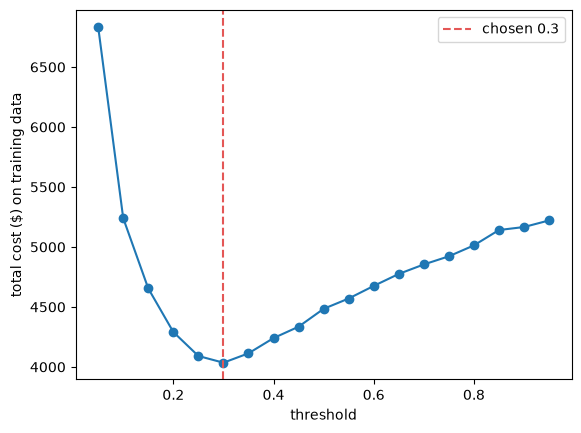

In [25]:
costs = pd.read_csv(reports / "threshold_costs.csv")
metrics = json.loads((reports / "metrics.json").read_text())
chosen = metrics["threshold"]

plt.plot(costs["threshold"], costs["cost"], marker="o")
plt.axvline(chosen, color="#e45756", linestyle="--", label=f"chosen {chosen}")
plt.xlabel("threshold")
plt.ylabel("total cost ($) on training data")
plt.legend()
plt.show()

 # Confusion matrix

In [26]:
cm = metrics["test"]["confusion_matrix"]
matrix = pd.DataFrame(
    [
        [cm["true_negative"], cm["false_positive"]],
        [cm["false_negative"], cm["true_positive"]],
    ],
    index=["actually on time", "actually late"],
    columns=["not flagged", "flagged"],
)
print(f"Threshold {chosen}")
print(matrix.to_string())
print()
for name in ["precision", "recall", "f1", "roc_auc"]:
    print(f"{name}: {metrics['test'][name]:.3f}")

Threshold 0.3
                  not flagged  flagged
actually on time          578       55
actually late              64       53

precision: 0.491
recall: 0.453
f1: 0.471
roc_auc: 0.796


# Cost of the three policies on the test set

flag_nobody       1755
flag_everybody    3000
model             1392

Model saves $363 against flagging nobody (21%)


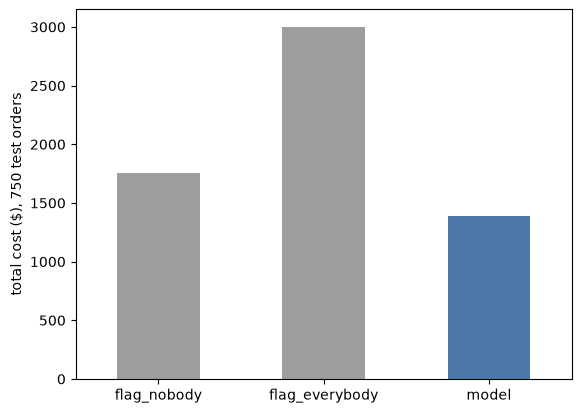

In [ ]:
policy = pd.Series(metrics["test_cost"])
print(policy.to_string())
print()
saving = metrics["saving_vs_flag_nobody"]
print(
    f"Model saves ${saving} against flagging nobody "
    f"({saving / policy['flag_nobody']:.0%})"
)

policy.plot.bar(color=["#9d9d9d", "#9d9d9d", "#4c78a8"], rot=0)
plt.ylabel("total cost ($), 750 test orders")
plt.show()

# Recommendations:
**-Would I use it?** Yes, as a pilot test. Across 750 unseen orders, the model successfully reduced total costs from $1,755 (doing nothing) down to $1,392 saving $363 (about 21%). Meanwhile, flagging every single order would cost $3k proving that the model delivers genuie value.

**-Why this threshold?** A voucher becomes financially worthwhile when the probability of lateness exceeds $4/$15, which is roughly 0.27. When scanning the training data using a 0.05 step grid, out of fold costs hit their minimun at 0.3. The test set was kept entirely untouched during this process.

**-Why did I exclue?** customer_rating was removed because customers submit ratings after delivery - including it introduces data leakage. oder_id was also dropped as it it merely an identifier. If the rating column is left in, the cross-validated ROC-AUC artificially jumps from 0.795 to 0,907 which reflects leakage rather than true predictive power.

**-One limitation:** The test set contains only 117 late orders, meaning the calculated savings carry some statistical uncertainty. Additionally, both the dataset and the cost values are entirely simulated.